# 29F — Reproducible Maintainability Triage Evaluation

**Purpose:** Demonstrate how the actual MLCQ classification metrics, PMD rule-aligned comparison, and grouping evaluation are calculated and plotted. No estimated values or invented ground truth.

**Run location:** Save this notebook to `Code Cleanliness/evaluation/notebooks/`, open in VS Code with the project's Python environment, then select **Run All** *for this evaluation notebook only* (never the Kaggle training notebook). The notebook finds your repository root automatically.

**Research caveats:** This is a balanced purposive MLCQ source subset (36 scored per concern); 1 of 72 staged Java files failed JavaParser; MLCQ Blob != automatically GOD_CLASS; sampled annotation intervals need independent AST-location auditing; PMD NcssCount and our Long Method have different rule definitions. These are **preliminary comparative figures**, not population-generalizable accuracy.


In [2]:
%pip install matplotlib pandas numpy scipy scikit-learn

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import json, csv, random
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
root = next((p for p in [cwd, *cwd.parents] if (p/'Code Cleanliness'/'evaluation').is_dir()), None)
if root is None:
    raise FileNotFoundError('Open this notebook inside the J26-SE-361 checkout.')
component = root/'Code Cleanliness'
final = component/'evaluation'/'results'/'final_evaluation'
(final/'graphs').mkdir(parents=True, exist_ok=True)
print('Repository:', root)
print('Evidence folder:', final)


Repository: C:\4th Year\Research Work\Implementation Stage\J26-SE-361
Evidence folder: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation


## 1. MLCQ classification metrics — recomputed from individual predictions

In [2]:
pred = pd.read_csv(final/'detection'/'per_sample_predictions.csv')
print('Input rows:', len(pred))
print('Fields:', list(pred.columns))
required = {'sample_id', 'smell', 'evaluation_status', 'gold', 'predicted'}
assert required.issubset(pred.columns), 'Missing required columns'
scored = pred.loc[pred['evaluation_status'].eq('SCORED')].copy()
assert scored['gold'].isin([0,1]).all() and scored['predicted'].isin([0,1]).all()

def binary_metrics(df, prediction='predicted'):
    g = df['gold'].astype(int); p = df[prediction].astype(int)
    tp = int(((g==1)&(p==1)).sum()); fp = int(((g==0)&(p==1)).sum())
    fn = int(((g==1)&(p==0)).sum()); tn = int(((g==0)&(p==0)).sum())
    precision = tp/(tp+fp) if tp+fp else float('nan')
    recall = tp/(tp+fn) if tp+fn else float('nan')
    f1 = 2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) else float('nan')
    return {'n':len(df),'TP':tp,'FP':fp,'FN':fn,'TN':tn,
            'precision':precision,'recall':recall,'f1':f1,'accuracy':(tp+tn)/len(df) if len(df) else float('nan')}

measured = pd.DataFrame([{'smell':smell,**binary_metrics(group)} for smell,group in scored.groupby('smell')])
display(measured)
reference = json.loads((final/'detection'/'metrics.json').read_text(encoding='utf-8'))['by_smell']
for row in measured.to_dict('records'):
    ref = reference[row['smell']]
    assert all(row[k] == ref[k] for k in ('n','TP','FP','FN','TN')), f'Frozen metrics disagree for {row["smell"]}'
print('PASS: recomputed confusion matrices match committed metrics.json')


Input rows: 80
Fields: ['sample_id', 'smell', 'gold', 'positive_votes', 'negative_votes', 'repository', 'commit_hash', 'path', 'start_line', 'end_line', 'link', 'source_url', 'downloaded_path', 'sha256', 'fetch_status', 'stage_status', 'staged_path', 'predicted', 'evaluation_status', 'notes']


,smell,n,TP,FP,FN,TN,precision,recall,f1,accuracy
0,blob,36,0,0,17,19,NaN,0.000000,0.00,0.527778
1,long method,36,8,0,9,19,1.0,0.470588,0.64,0.750000


PASS: recomputed confusion matrices match committed metrics.json


Saved: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\graphs\recomputed_blob_confusion_matrix.png


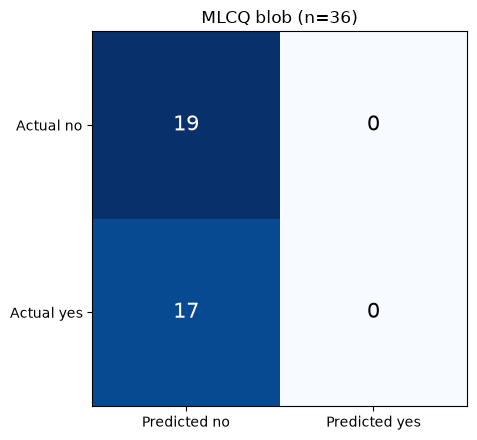

Saved: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\graphs\recomputed_long_method_confusion_matrix.png


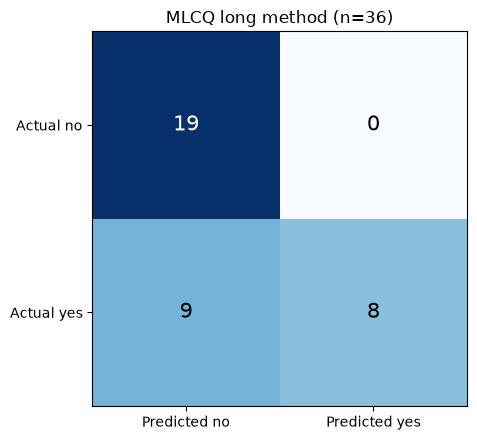

In [3]:
for item in measured.to_dict('records'):
    arr = np.array([[item['TN'],item['FP']],[item['FN'],item['TP']]], dtype=int)
    fig,ax=plt.subplots(figsize=(5.5,4.5))
    ax.imshow(arr, cmap='Blues')
    for (i,j),value in np.ndenumerate(arr):
        ax.text(j,i,str(value),ha='center',va='center',fontsize=15,
                color='white' if value>arr.max()/2 else 'black')
    ax.set_xticks([0,1],['Predicted no','Predicted yes'])
    ax.set_yticks([0,1],['Actual no','Actual yes'])
    ax.set_title(f'MLCQ {item["smell"]} (n={item["n"]})')
    fig.tight_layout()
    destination = final/'graphs'/('recomputed_'+item['smell'].replace(' ','_')+'_confusion_matrix.png')
    fig.savefig(destination,dpi=160,bbox_inches='tight')
    print('Saved:',destination)
    plt.show()


## 2. Preliminary PMD comparison — from saved per-sample matching table

PMD `NcssCount` is a **partial proxy** for Long Method. PMD `GodClass` and MLCQ Blob have different definitions. The PMD sample matching CSV was initially generated via PowerShell; the raw `pmd.xml` is excluded from Git. This notebook validates the *saved* per-sample arithmetic. Do not claim reproduction of the PMD matching algorithm until its exporter has also been committed.

In [4]:
comp=pd.read_csv(final/'baselines'/'mlcq_pmd_comparison.csv')
assert {'sample_id','smell','gold','our_prediction','pmd_prediction','pmd_file_found'}.issubset(comp.columns)
assert len(comp)==len(scored)
assert not comp['sample_id'].duplicated().any(), 'Duplicate MLCQ sample IDs'
assert set(comp['sample_id'].astype(str))==set(scored['sample_id'].astype(str))
rows=[]
for smell,group in comp.groupby('smell'):
    for label,pred_column in [('Our analyzer','our_prediction'),('PMD proxy','pmd_prediction')]:
        rows.append({'smell':smell,'system':label,**binary_metrics(group, pred_column)})
benchmark=pd.DataFrame(rows)
display(benchmark)
print('PMD XML files with violation entries:', comp.groupby('smell')['pmd_file_found'].sum().to_dict())
print('CAUTION: Missing <file> nodes may mean zero violations; full scan coverage is not proven by this table.')


,smell,system,n,TP,FP,FN,TN,precision,recall,f1,accuracy
0,blob,Our analyzer,36,0,0,17,19,NaN,0.000000,0.000000,0.527778
1,blob,PMD proxy,36,9,0,8,19,1.0,0.529412,0.692308,0.777778
2,long method,Our analyzer,36,8,0,9,19,1.0,0.470588,0.640000,0.750000
3,long method,PMD proxy,36,2,0,15,19,1.0,0.117647,0.210526,0.583333


PMD XML files with violation entries: {'blob': 28, 'long method': 31}
CAUTION: Missing <file> nodes may mean zero violations; full scan coverage is not proven by this table.


Saved: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\graphs\preliminary_mlcq_pmd_f1_comparison.png


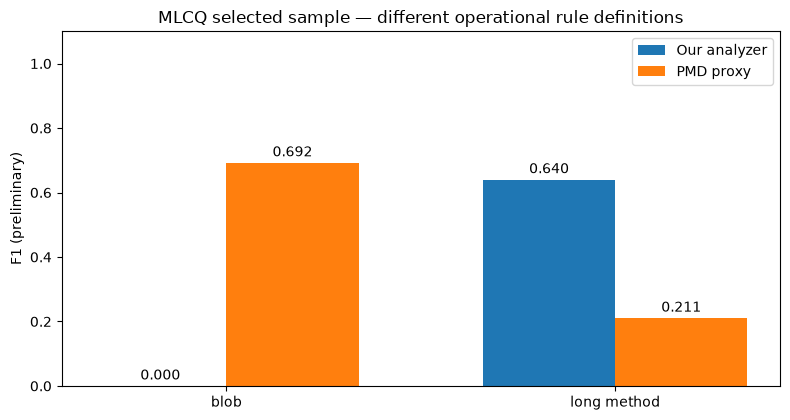

In [5]:
fig,ax=plt.subplots(figsize=(8,4.3))
labels=benchmark['smell'].unique().tolist()
x=np.arange(len(labels)); width=.34
for idx,system in enumerate(['Our analyzer','PMD proxy']):
    part=benchmark.set_index(['smell','system'])
    values=[part.loc[(label,system),'f1'] for label in labels]
    bars=ax.bar(x+(idx-.5)*width,values,width,label=system)
    for b,v in zip(bars,values): ax.text(b.get_x()+b.get_width()/2,b.get_height()+.02,f'{v:.3f}',ha='center',fontsize=10)
ax.set_xticks(x,labels);ax.set_ylim(0,1.1);ax.set_ylabel('F1 (preliminary)')
ax.set_title('MLCQ selected sample — different operational rule definitions')
ax.legend();fig.tight_layout()
p=final/'graphs'/'preliminary_mlcq_pmd_f1_comparison.png'
fig.savefig(p,dpi=160,bbox_inches='tight');print('Saved:',p);plt.show()


## 3. Grouping evaluation — independent pair labels required

The system's grouping output can be evaluated using **pairwise precision/recall/F1**. We do **not** manufacture ground-truth relationships from the analyzer's own groups; that would cause circular evaluation. Instead, we export candidate pairs from actual analyzer findings. An independent reviewer must mark whether two findings refer to the **same underlying maintainability concern** using code/source context, with `gold_same_issue=1` or `0`, and preserve the review notes.

The sampler is deterministic and uses both within-group and between-group pairs. **Do not report grouping performance until the independent labels have been completed.**

In [6]:
evidence_path=component/'datasets'/'processed'/'mlcq_29f'/'source_batch'/'analyzer_evidence.json'
print('Analyzer evidence exists:',evidence_path.exists())
if evidence_path.exists():
    obj=json.loads(evidence_path.read_text(encoding='utf-8'))
    groups=obj.get('ranked_groups',[])
    print('Ranked groups:',len(groups))
    if groups:
        print('First group keys:',list(groups[0].keys()))
        print('First group findings container types:',{k:type(v).__name__ for k,v in groups[0].items() if 'finding' in k.lower() or 'issue' in k.lower()})
else:
    print('Run analyzer or locate analyzer_evidence.json before constructing independent grouping-review candidates.')


Analyzer evidence exists: True
Ranked groups: 4461
First group keys: ['group_id', 'rank', 'exceedance_score', 'distinct_concern_count', 'affected_file_count', 'supported_finding_count', 'ranking_explanation', 'findings']
First group findings container types: {'supported_finding_count': 'int', 'findings': 'list'}


In [7]:
from itertools import combinations
# Candidate-generation uses only explicit finding_id values and their group membership.
# If the Java JSON uses a different nested structure, inspect the preceding cell
# and update extract_findings() explicitly before interpreting any metrics.
def extract_findings(g):
    for key in ('findings','related_findings','issues'):
        xs=g.get(key)
        if isinstance(xs,list): return [x for x in xs if isinstance(x,dict) and x.get('finding_id')]
    return []

review_csv=final/'grouping'/'pairwise_independent_review.csv'
review_csv.parent.mkdir(parents=True,exist_ok=True)
if evidence_path.exists():
    grouped=[]
    for gi,g in enumerate(groups):
        findings=extract_findings(g)
        if findings: grouped.append((gi,findings))
    within=[];between=[]
    for gi,fs in grouped:
        for a,b in combinations(fs,2):
            within.append((a,b,1))
    for (gi,fa),(gj,fb) in combinations(grouped,2):
        # Different groups: pair only findings referencing the same source file.
        a_by={}
        for a in fa: a_by.setdefault(a.get('source_file'),[]).append(a)
        for b in fb:
            if b.get('source_file') in a_by:
                for a in a_by[b.get('source_file')]:between.append((a,b,0))
    rng=random.Random(29)
    rng.shuffle(within);rng.shuffle(between)
    sampled=within[:min(80,len(within))]+between[:min(80,len(between))]
    records=[];seen=set()
    for a,b,sys_same in sampled:
        ids=sorted([str(a['finding_id']),str(b['finding_id'])]);pair=tuple(ids)
        if pair in seen:continue
        seen.add(pair)
        records.append({'finding_a':ids[0],'finding_b':ids[1],
                        'system_same_group':sys_same,'gold_same_issue':'','reviewer_notes':''})
    if records and not review_csv.exists():
        pd.DataFrame(records).to_csv(review_csv,index=False)
        print('Review template created:',review_csv,'pairs:',len(records))
    elif review_csv.exists():print('Preserved existing reviewer file:',review_csv)
    else:print('No eligible candidate pairs; inspect group JSON structure and sample a suitable repository.')


Review template created: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\grouping\pairwise_independent_review.csv pairs: 160


In [8]:
if review_csv.exists():
    review=pd.read_csv(review_csv,dtype={'gold_same_issue':str}).fillna('')
    labels=review['gold_same_issue'].astype(str).str.strip()
    valid=labels.isin(['0','1'])
    print(f'Independent reviewer labels: {valid.sum()} / {len(review)}')
    if valid.all() and len(review)>0:
        evaluated=review.copy()
        evaluated['gold']=labels.astype(int)
        evaluated['predicted']=evaluated['system_same_group'].astype(int)
        group_result=binary_metrics(evaluated)
        display(pd.DataFrame([group_result]))
        (final/'grouping'/'pairwise_metrics.json').write_text(json.dumps(group_result,indent=2),encoding='utf-8')
        fig,ax=plt.subplots(figsize=(5.6,4.2))
        ax.bar(['Precision','Recall','F1'],[group_result['precision'],group_result['recall'],group_result['f1']])
        ax.set_ylim(0,1.05);ax.set_title('Grouping — independent pairwise validation');fig.tight_layout()
        fig.savefig(final/'graphs'/'grouping_pairwise_validation.png',dpi=160);plt.show()
    else:
        print('No grouping scores/graphs generated: independent review is incomplete.')


Independent reviewer labels: 0 / 160
No grouping scores/graphs generated: independent review is incomplete.


## 4. Commit / audit notes

- Commit this notebook under `Code Cleanliness/evaluation/notebooks/`.
- Commit only the **curated** figures/tables/independently reviewed labels. `.gitignore` currently excludes `evaluation/results/`; use `git add -f` on the specific final-evaluation package after inspecting for sensitive/private content.
- The source MLCQ and PMD per-sample CSVs are committed under `evaluation/results/final_evaluation/`.
- For grouping, record who reviewed which relationships, when, and using what definition; never infer the independent label from the predicted group.
- Ranking Spearman/Top-k needs **independently assessed priorities**; Qwen quality needs blinded human ratings; runtime/memory need actual benchmark traces. They are separate experiments, not values to infer from this notebook.


In [9]:
import json
import pandas as pd
from pathlib import Path

evidence = Path(
    r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361"
    r"\Code Cleanliness\datasets\processed\mlcq_29f"
    r"\source_batch\analyzer_evidence.json"
)

data = json.loads(evidence.read_text(encoding="utf-8"))
groups = data["ranked_groups"]

ranking = pd.DataFrame([
    {
        "group_id": g["group_id"],
        "analyzer_rank": g["rank"],
        "exceedance_score": g["exceedance_score"],
        "concerns": g["distinct_concern_count"],
        "affected_files": g["affected_file_count"],
        "findings": g["supported_finding_count"],
        "independent_priority_rank": ""
    }
    for g in groups[:40]
])

output = Path(
    r"C:\4th Year\Research Work\Implementation Stage\J26-SE-361"
    r"\Code Cleanliness\evaluation\results"
    r"\final_evaluation\ranking"
)

output.mkdir(parents=True, exist_ok=True)
ranking.to_csv(output / "ranking_independent_review.csv", index=False)

print("Ranking review template:", output / "ranking_independent_review.csv")
print("Groups prepared:", len(ranking))

Ranking review template: C:\4th Year\Research Work\Implementation Stage\J26-SE-361\Code Cleanliness\evaluation\results\final_evaluation\ranking\ranking_independent_review.csv
Groups prepared: 40


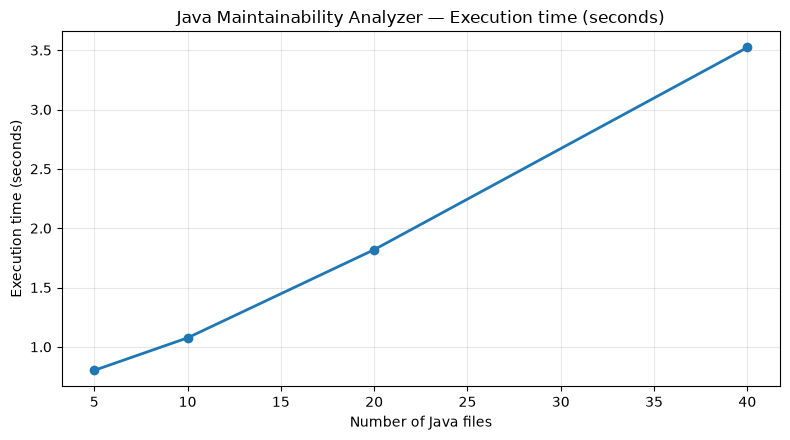

Saved: java_runtime_scalability.png


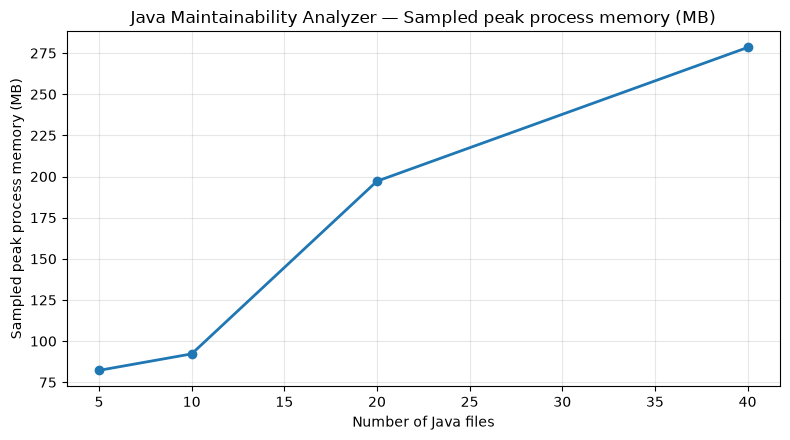

Saved: java_memory_scalability.png


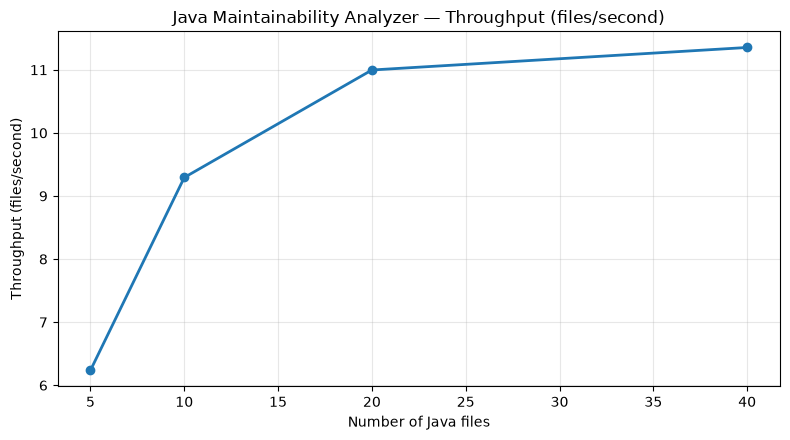

Saved: java_throughput_scalability.png


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

results = root / "Code Cleanliness" / "evaluation" / "results" / "final_evaluation"
df = pd.read_csv(results / "scalability" / "java_analyzer_scalability.csv")

plots = [
    ("runtime_seconds", "Execution time (seconds)", "java_runtime_scalability.png"),
    ("sampled_peak_working_set_mb", "Sampled peak process memory (MB)", "java_memory_scalability.png"),
    ("throughput_files_per_second", "Throughput (files/second)", "java_throughput_scalability.png"),
]

for column, ylabel, filename in plots:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(df["java_files"], df[column], marker="o", linewidth=2)
    ax.set_xlabel("Number of Java files")
    ax.set_ylabel(ylabel)
    ax.set_title("Java Maintainability Analyzer — " + ylabel)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(results / "graphs" / filename, dpi=200)
    plt.show()
    plt.close(fig)
    print("Saved:", filename)